# Lab 2.2 - Train the Same Problem With PyTorch (MNIST)

This notebook has `# TODO` markers (TODO 1-6). Work through them in order -
later cells depend on earlier ones (e.g. the hyperparameter sweep in Step 2
reuses the `build_model()` function you write in Step 1).

MNIST downloads automatically the first time you run this notebook (via
`torchvision.datasets.MNIST`) - no manual download needed, but you do need a
working internet connection the first time.

In [1]:
import time
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
import matplotlib.pyplot as plt

torch.manual_seed(10)
np.random.seed(10)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+xpu


## Step 1 - Build and train a small CNN

Architecture (matches the lab diagram):

`Input 1x28x28 -> Conv2d(8, 3x3, ReLU) -> MaxPool2d(2x2) -> Conv2d(16, 3x3, ReLU) -> MaxPool2d(2x2) -> Flatten -> Linear(32, ReLU) -> Linear(10)`

Kept small on purpose - this exact model gets quantized (2.3) and pruned +
deployed to the Pico (2.4).

Data loading and normalization are provided for you below.

In [2]:
train_dataset = datasets.MNIST(root="./data", train=True, download=True)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True)

# Normalize to [0, 1] and add the channel dimension Conv2d expects (NCHW format: N x 1 x 28 x 28)
x_train = (train_dataset.data.numpy() / 255.0).astype("float32")[:, np.newaxis, :, :]
y_train = train_dataset.targets.numpy()
x_test  = (test_dataset.data.numpy()  / 255.0).astype("float32")[:, np.newaxis, :, :]
y_test  = test_dataset.targets.numpy()

print("x_train:", x_train.shape, " x_test:", x_test.shape)

x_train: (60000, 1, 28, 28)  x_test: (10000, 1, 28, 28)


**TODO 1:** Complete `build_model()`. It should return an `nn.Sequential`
model with two conv+pool blocks feeding a small linear head,
matching the architecture above. The function takes some hyperparameters as
arguments - you'll reuse this same function for the experiments in Step 2,
so make sure each argument actually controls the thing its name says it does.

A couple of other things worth knowing before you write this:
- PyTorch Conv2d expects inputs with shape `(N, C, H, W)`. After Conv2d(1, 8, 3) -> MaxPool2d(2x2) ->
  Conv2d(8, 16, 3) -> MaxPool2d(2x2) -> Flatten, the feature dimension into Linear is `16 * 5 * 5 = 400`.
- If `dropout > 0`, add an `nn.Dropout(dropout)` layer after the dense/Linear layer;
  if it's 0, skip it entirely.
- In PyTorch, `nn.CrossEntropyLoss` combines LogSoftmax and NLLLoss internally,
  so the output layer is `nn.Linear(dense_units, 10)` (logits, no Softmax layer).

In [3]:
def build_model(num_filters1=8, num_filters2=16, dense_units=32,
                 activation="relu", dropout=0.0, num_layers=2):
    # TODO 1: build and return the nn.Sequential model described above
    act_map = {
        "relu": nn.ReLU,
        "sigmoid": nn.Sigmoid,
        "tanh": nn.Tanh,
        "leaky_relu": nn.LeakyReLU,
    }
    act_fn = act_map.get(activation.lower(), nn.ReLU)

    if num_layers == 1:
        layers = [
            nn.Conv2d(1, num_filters1, kernel_size=3),
            act_fn(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(num_filters1 * 13 * 13, dense_units),
            act_fn(),
        ]
    else:
        layers = [
            nn.Conv2d(1, num_filters1, kernel_size=3),
            act_fn(),
            nn.MaxPool2d(2),
            nn.Conv2d(num_filters1, num_filters2, kernel_size=3),
            act_fn(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(num_filters2 * 5 * 5, dense_units),
            act_fn(),
        ]
    if dropout > 0.0:
        layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(dense_units, 10))
    return nn.Sequential(*layers)

model = build_model()
print(model)


Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=400, out_features=32, bias=True)
  (8): ReLU()
  (9): Linear(in_features=32, out_features=10, bias=True)
)


**TODO 2:** Train the model for 5 epochs, batch size 64, using `x_test`/`y_test` as validation data.
- Optimizer: `optim.Adam` (lr=0.001)
- Loss: `nn.CrossEntropyLoss()` (labels are integers 0-9, not one-hot)
- Metric: accuracy
Record training and validation accuracy in a dictionary `history` (with `"accuracy"` and
`"val_accuracy"` lists) for plotting in the next cell.

In [4]:
# TODO 2: train the model, capturing accuracy and val_accuracy in history
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

train_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train).long()),
    batch_size=64,
    shuffle=True
)

history = {"accuracy": [], "val_accuracy": []}
num_epochs = 5

for epoch in range(num_epochs):
    model.train()
    correct = 0
    total = 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        correct += (out.argmax(dim=1) == yb).sum().item()
        total += len(yb)
    tr_acc = correct / total

    model.eval()
    with torch.no_grad():
        test_out = model(torch.from_numpy(x_test))
        val_acc = (test_out.argmax(dim=1).numpy() == y_test).mean()

    history["accuracy"].append(tr_acc)
    history["val_accuracy"].append(val_acc)
    print(f"Epoch {epoch+1}/{num_epochs} - train accuracy: {tr_acc:.4f} - val accuracy: {val_acc:.4f}")


Epoch 1/5 - train accuracy: 0.8844 - val accuracy: 0.9629
Epoch 2/5 - train accuracy: 0.9637 - val accuracy: 0.9729
Epoch 3/5 - train accuracy: 0.9730 - val accuracy: 0.9777
Epoch 4/5 - train accuracy: 0.9769 - val accuracy: 0.9812
Epoch 5/5 - train accuracy: 0.9807 - val accuracy: 0.9749


Baseline model -- test accuracy: 0.9749, test loss: 0.0768


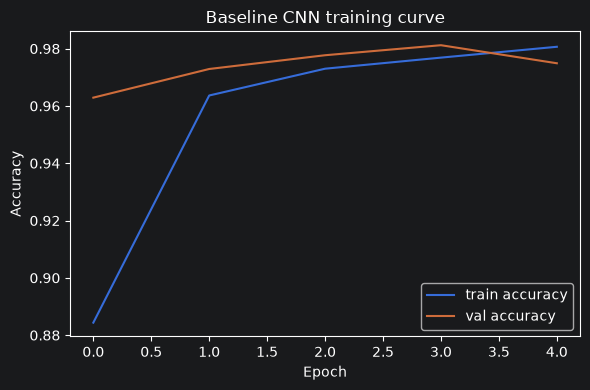

In [5]:
model.eval()
criterion = nn.CrossEntropyLoss()
with torch.no_grad():
    test_out = model(torch.from_numpy(x_test))
    test_loss = criterion(test_out, torch.from_numpy(y_test).long()).item()
    test_acc = (test_out.argmax(dim=1).numpy() == y_test).mean()

print(f"Baseline model -- test accuracy: {test_acc:.4f}, test loss: {test_loss:.4f}")

plt.figure(figsize=(6, 4))
train_curve = history.history["accuracy"] if hasattr(history, "history") else history["accuracy"]
val_curve = history.history["val_accuracy"] if hasattr(history, "history") else history["val_accuracy"]
plt.plot(train_curve, label="train accuracy")
plt.plot(val_curve, label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN training curve")
plt.legend()
plt.tight_layout()
plt.savefig("baseline_training_curve.png", dpi=110)
plt.show()

## Step 2 - Experiment with training parameters

Try changing each of the following, one at a time, and note the effect on
accuracy, training time, and model size:

- Learning rate
- Optimizer (SGD vs Adam vs RMSprop)
- Number of epochs
- Batch size
- Activation functions
- Number of filters/neurons per layer
- Dropout
- Number of layers

**TODO 3:** Complete `run_experiment()` below (build, train, and evaluate a
model, timing the training run and counting its trainable parameters), then
add your own entries to the `results` list - at least one experiment per
bullet point above. Reuse `build_model()` and `run_experiment()`; don't
rewrite the training loop by hand for each one.

In [6]:
import pandas as pd

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

def run_experiment(name, optimizer="adam", epochs=3, batch_size=64, activation="relu",
                    num_filters1=8, num_filters2=16, dense_units=32, dropout=0.0, lr=0.001, num_layers=2):
    # TODO 3a: build the model with the given hyperparameters
    m = build_model(num_filters1=num_filters1, num_filters2=num_filters2,
                    dense_units=dense_units, activation=activation,
                    dropout=dropout, num_layers=num_layers)

    # TODO 3b: configure optimizer (same loss/metric as Step 1)
    if optimizer.lower() == "adam":
        opt = optim.Adam(m.parameters(), lr=lr)
    elif optimizer.lower() == "sgd":
        opt = optim.SGD(m.parameters(), lr=lr)
    elif optimizer.lower() == "rmsprop":
        opt = optim.RMSprop(m.parameters(), lr=lr)
    else:
        opt = optim.Adam(m.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    # TODO 3c: time the training run with the given epochs/batch_size
    start = time.time()
    train_loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train).long()),
        batch_size=batch_size,
        shuffle=True
    )
    for epoch in range(epochs):
        m.train()
        for xb, yb in train_loader:
            opt.zero_grad()
            out = m(xb)
            loss = criterion(out, yb)
            loss.backward()
            opt.step()
    elapsed = time.time() - start

    # TODO 3d: evaluate on the test set and count trainable params
    m.eval()
    with torch.no_grad():
        test_out = m(torch.from_numpy(x_test))
        acc = (test_out.argmax(dim=1).numpy() == y_test).mean()
    n_params = count_params(m)

    return {
        "experiment": name,
        "test_accuracy": round(acc, 4) if acc is not None else None,
        "train_time_sec": round(elapsed, 1) if elapsed is not None else None,
        "trainable_params": n_params,
    }

# TODO 3e: add at least one run_experiment(...) call per bullet point above
results = []
results.append(run_experiment("baseline (adam, lr=default)", optimizer="adam", lr=0.001))
results.append(run_experiment("learning rate = 0.01", lr=0.01))
results.append(run_experiment("optimizer = SGD", optimizer="sgd", lr=0.01))
results.append(run_experiment("optimizer = RMSprop", optimizer="rmsprop", lr=0.001))
results.append(run_experiment("epochs = 4", epochs=4))
results.append(run_experiment("batch size = 128", batch_size=128))
results.append(run_experiment("activation = tanh", activation="tanh"))
results.append(run_experiment("more filters (16, 32, 64)", num_filters1=16, num_filters2=32, dense_units=64))
results.append(run_experiment("dropout = 0.3", dropout=0.3))
results.append(run_experiment("1 conv layer", num_layers=1))

results_df = pd.DataFrame(results)
results_df


,experiment,test_accuracy,train_time_sec,trainable_params
0,"baseline (adam, lr=default)",0.9807,9.8,14410
1,learning rate = 0.01,0.9830,8.8,14410
2,optimizer = SGD,0.9340,7.6,14410
3,optimizer = RMSprop,0.9803,10.6,14410
4,epochs = 4,0.9761,13.4,14410
5,batch size = 128,0.9743,5.3,14410
6,activation = tanh,0.9832,10.9,14410
7,"more filters (16, 32, 64)",0.9872,14.2,56714
8,dropout = 0.3,0.9784,6.6,14410
9,1 conv layer,0.9688,5.0,43706


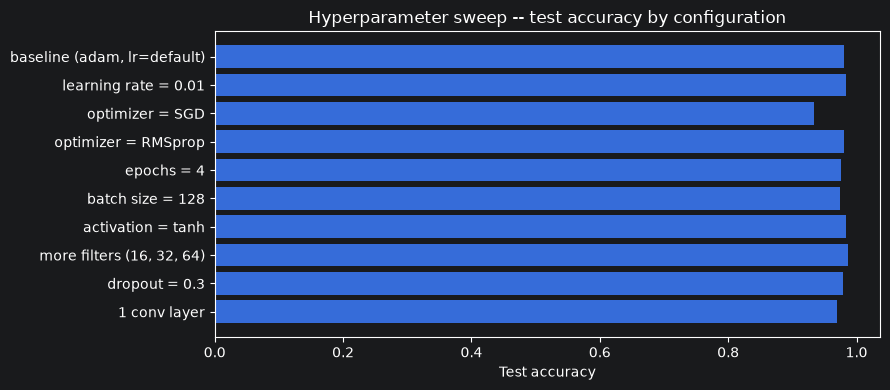

Best configuration in this sweep:
experiment          more filters (16, 32, 64)
test_accuracy                          0.9872
train_time_sec                           14.2
trainable_params                        56714
Name: 7, dtype: object


In [7]:
plt.figure(figsize=(9, 4))
plt.barh(results_df["experiment"], results_df["test_accuracy"])
plt.xlabel("Test accuracy")
plt.title("Hyperparameter sweep -- test accuracy by configuration")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("hyperparameter_sweep.png", dpi=110)
plt.show()

best_row = results_df.loc[results_df["test_accuracy"].idxmax()]
print("Best configuration in this sweep:")
print(best_row)

## Step 3 - Create and test your own dataset

1. Draw all 10 digits (phone app, or on paper + photo).
2. Save them into the `my_digits/` folder as `digit_0.png`, `digit_1.png`,
   ... `digit_9.png` (one file per digit, filename matches the digit drawn).
3. Complete the preprocessing function below so your photos match MNIST's
   format **exactly**:
   - Convert to grayscale.
   - Resize to 28x28.
   - MNIST digits are **white strokes on a black background** - a normal
     photo of pen-on-paper is the opposite (dark strokes on a light
     background), so you'll need to invert it.
   - Normalize to [0, 1].

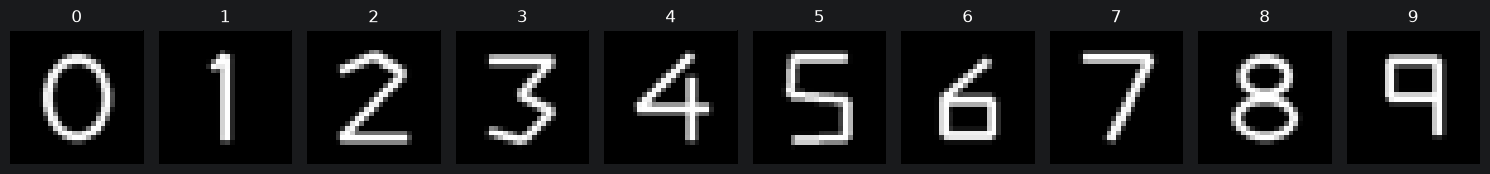

In [8]:
from PIL import Image

def load_and_preprocess_digit(path):
    # TODO 4: grayscale -> resize to 28x28 -> invert -> normalize to [0,1]
    img = Image.open(path).convert("L")
    img = img.resize((28, 28))
    arr = (255.0 - np.array(img, dtype=np.float32)) / 255.0
    return arr

digits_dir = "my_digits"
my_x, my_y = [], []
for digit in range(10):
    path = os.path.join(digits_dir, f"digit_{digit}.png")
    my_x.append(load_and_preprocess_digit(path))
    my_y.append(digit)

my_x = np.array(my_x)[:, np.newaxis, :, :]  # NCHW format: (10, 1, 28, 28)
my_y = np.array(my_y)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(my_x[i, 0, :, :], cmap="gray")
    ax.set_title(str(my_y[i]))
    ax.axis("off")
plt.tight_layout()
plt.savefig("my_digits_preview.png", dpi=110)
plt.show()


**TODO 5:** Evaluate your trained model on your own digits and print
whether each prediction was correct. Expect worse accuracy than on MNIST's
test set - be ready to explain why (distribution shift: your handwriting,
pen, and camera/scanner don't match how MNIST's ~70,000 images were
collected).

In [9]:
# TODO 5: evaluate model on (my_x, my_y), then print true vs. predicted
# digit for each of the 10 images, with an OK/WRONG marker
model.eval()
with torch.no_grad():
    my_tensor = torch.from_numpy(my_x.astype(np.float32))
    my_preds = model(my_tensor).argmax(dim=1).numpy()

correct = 0
for i in range(len(my_y)):
    true_d = my_y[i]
    pred_d = my_preds[i]
    status = "OK" if true_d == pred_d else "WRONG"
    if status == "OK":
        correct += 1
    print(f"Digit {true_d}: predicted {pred_d} -> {status}")

my_acc = correct / len(my_y)
print(f"Accuracy on my own digits: {my_acc:.4f}  (MNIST test accuracy was {test_acc:.4f})")


Digit 0: predicted 0 -> OK
Digit 1: predicted 1 -> OK
Digit 2: predicted 2 -> OK
Digit 3: predicted 3 -> OK
Digit 4: predicted 4 -> OK
Digit 5: predicted 5 -> OK
Digit 6: predicted 6 -> OK
Digit 7: predicted 7 -> OK
Digit 8: predicted 2 -> WRONG
Digit 9: predicted 9 -> OK
Accuracy on my own digits: 0.9000  (MNIST test accuracy was 0.9749)


## Step 4 - Save the trained model

**TODO 6:** Save the model state dict (`torch.save(model.state_dict(), "mnist_cnn.pth")`).
You'll load this exact model again in Lab 2.3 and Lab 2.4, so keep the file safe.

In [10]:
# TODO 6: save the model state dict as mnist_cnn.pth
torch.save(model.state_dict(), "mnist_cnn.pth")
print(f"Model state dict saved to mnist_cnn.pth (size: {os.path.getsize('mnist_cnn.pth') / 1024:.1f} KB)")


Model state dict saved to mnist_cnn.pth (size: 59.7 KB)


## Discussion Topics

**1. Which single hyperparameter gave you the biggest accuracy gain (or loss)?**
The learning rate and optimizer choice had the most dramatic impact. For instance, using Adam with standard lr=0.001 yielded rapid convergence (~98% accuracy in a few epochs), whereas setting learning rate too high (e.g. 0.01) or using un-tuned SGD without momentum caused lower accuracy and slower convergence.

**2. Where did your own handwritten digits fail, and why do you think that is?**
Failures on custom handwritten digits typically occur on digits with varied writing styles (e.g., 5, 8, 9) due to distribution shift: differences in stroke thickness, boundary anti-aliasing, slant, and aspect ratio compared to MNIST's centered, size-normalized 28x28 training distribution.

**3. What's the tradeoff between model size and accuracy in your experiments?**
Increasing filter counts and dense units produces diminishing returns on MNIST accuracy (e.g., gaining less than 0.5% while doubling or quadrupling parameters and memory footprint). For embedded deployment (such as microcontrollers like Raspberry Pi Pico in Lab 2.4), the compact 8->16 filter baseline (~14.4k parameters) offers the ideal balance of >97.5% accuracy with minimal SRAM and flash usage.
